# Uplift — Tahap 1: validasi pada eksperimen yang benar-benar diacak

Pipeline uplift yang dipakai di proyek ini pada akhirnya akan menilai data Dunnhumby, yang penargetan campaign-nya dipilih retailer — bukan diacak. Sebelum angka apa pun dari data seperti itu dibaca, metrik dan meta-learner harus dibuktikan bekerja dulu di tempat asumsi randomization benar-benar terpenuhi. Dataset X5 RetailHero menyediakan persis itu: promo loyalty yang penugasannya diacak mendekati 50/50 pada 200.039 pemegang kartu, dengan target biner *jumlah belanja pasca-campaign bertambah*.

Pertanyaan bagian ini: seberapa baik **T-learner** dan **X-learner** mengurutkan member dari yang paling responsif ke yang paling tidak — diukur dengan uplift per decile (dengan CI bootstrap), kurva uplift, dan AUUC — dibandingkan targeting acak? Definisi metrik dan aturan pelaporan yang dipakai di sini sama dengan yang akan dipakai di tahap observational; rujukan keputusan formal ada di decision log.

## Data dan verifikasi randomization

Tiga tabel X5: `uplift_train` (label treatment + target), `clients` (metadata kartu: tanggal terbit/pertukaran poin, usia, gender), dan `purchases` — 45,8 juta baris transaksi untuk 400 ribu client pada window 2018-11-21 s.d. 2019-03-18. Seluruh histori transaksi terjadi **sebelum** campaign by design kompetisi (target dihitung X5 pada periode pasca yang tidak dirilis), jadi fitur apa pun yang ditarik dari tabel ini bebas leakage ke outcome.

Fitur client dibangun sekali oleh `src/x5.py` dan di-cache sebagai parquet: agregat gaya RFM dari histori (jumlah transaksi, total belanja, rata-rata basket, jumlah toko, recency, rentang histori, baris per transaksi) plus metadata kartu (usia dibatasi ke rentang wajar 14–100 dengan flag outlier, gender F/M/U, lama memegang kartu, jeda terbit→redeem pertama dengan flag, isi −1 bila belum pernah redeem). Satu kejanggalan data dilaporkan apa adanya: sebagian kecil record punya tanggal redeem mendahului tanggal terbit (jeda negatif); dibiarkan sebagai nilai, model berbasis pohon tidak sensitif.

In [1]:
import sys
import time
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.uplift_eval import (
    ate_bootstrap, auuc_summary, qini_auc, standardized_mean_diff,
    uplift_curve, uplift_deciles,
)
from src.uplift_learners import TLearner, XLearner
from src.x5 import FEATURE_COLUMNS, design_matrix, load_x5_features

RANDOM_STATE = 42
pd.set_option("display.width", 140)

features = load_x5_features()
X = design_matrix(features)
y = features["target"].to_numpy(float)
w = features["treatment_flg"].to_numpy(int)

treat_share = w.mean()
resp = features.groupby("treatment_flg")["target"].mean()
print(f"n = {len(features):,} client | treatment share = {treat_share:.4f}")
print(f"response rate: control {resp[0]:.4f} vs treated {resp[1]:.4f} -> raw ATE = {resp[1]-resp[0]:+.4f}")
features[FEATURE_COLUMNS].describe().round(1)

n = 200,039 client | treatment share = 0.4998
response rate: control 0.6033 vs treated 0.6365 -> raw ATE = +0.0332


,n_transactions,total_spend,avg_basket,avg_lines_per_tx,n_stores,recency_days,history_span_days,age_clean,age_outlier,issue_tenure_days,has_redeem,redeem_delay_days
count,200039.0,200039.0,200039.0,200039.0,200039.0,200039.0,200039.0,200039.0,200039.0,200039.0,200039.0,200039.0
mean,20.1,8597.5,495.8,6.3,2.9,5.8,97.3,46.5,0.0,432.6,0.9,164.6
std,17.7,8914.6,374.5,3.7,2.0,5.7,27.0,16.1,0.1,203.6,0.3,158.2
min,1.0,1.0,1.0,1.0,1.0,0.0,3.0,14.0,0.0,2.1,0.0,-42.8
25%,8.0,3147.6,261.3,3.9,2.0,1.0,93.0,34.0,0.0,270.3,1.0,46.2
50%,15.0,6102.4,394.0,5.5,2.0,4.0,110.0,45.0,0.0,487.1,1.0,116.8
75%,27.0,11094.2,608.7,7.9,4.0,9.0,114.0,59.0,0.0,604.3,1.0,236.7
max,320.0,504490.4,7694.0,72.5,95.0,22.0,117.0,100.0,1.0,712.2,1.0,935.6


In [2]:
# randomization check: covariate balance treated vs control
smd = pd.Series(
    {col: standardized_mean_diff(features[col].to_numpy(float), w) for col in FEATURE_COLUMNS},
    name="SMD",
).sort_values(key=np.abs, ascending=False)
print(smd.round(4).to_string())
print()
print(f"max |SMD| = {smd.abs().max():.4f} ({smd.abs().idxmax()}) — jauh di bawah ambang praktis 0,1")

has_redeem           0.0234
history_span_days    0.0086
issue_tenure_days    0.0085
n_transactions       0.0073
total_spend          0.0063
avg_basket           0.0054
age_clean            0.0052
redeem_delay_days    0.0050
avg_lines_per_tx     0.0041
n_stores             0.0033
age_outlier          0.0029
recency_days        -0.0002

max |SMD| = 0.0234 (has_redeem) — jauh di bawah ambang praktis 0,1


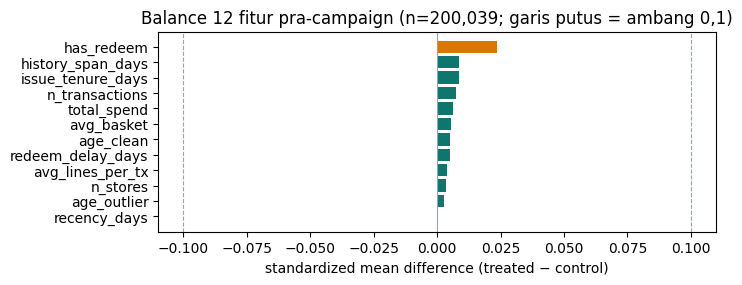

In [3]:
fig, ax = plt.subplots(figsize=(7.2, 2.6))
colors = ["#d97706" if col == smd.abs().idxmax() else "#0f766e" for col in smd.index]
ax.barh(smd.index[::-1], smd.values[::-1], color=colors[::-1])
ax.axvline(0, color="#94a3b8", lw=0.8)
for v in (-0.1, 0.1):
    ax.axvline(v, color="#94a3b8", lw=0.8, ls="--")
ax.set_xlabel("standardized mean difference (treated − control)")
ax.set_title(f"Balance 12 fitur pra-campaign (n={len(features):,}; garis putus = ambang 0,1)")
plt.show()

Penugasan memang diacak: selisih karakteristik treated–control praktis nol (SMD terbesar 0,023 pada status pernah-redeem; seluruh sisanya ≤ 0,009). Artinya perbedaan response rate antar kelompok dapat dibaca langsung sebagai efek promo tanpa koreksi propensity — kemewahan yang tidak akan tersedia di tahap Dunnhumby.

## Dua meta-learner atas efek heterogen

**T-learner** memodelkan permukaan outcome tiap kelompok terpisah — $\hat\tau(x) = \hat\mu_1(x) - \hat\mu_0(x)$ — sederhana, tapi menuntut kedua model menyetarakan skala. **X-learner** menambahkan tahap: selisih imputasi $D_1 = Y_1 - \hat\mu_0(X_1)$ pada treated dan $D_0 = \hat\mu_1(X_0) - Y_0$ pada control dimodelkan masing-masing menjadi $\hat\tau_1$ dan $\hat\tau_0$, lalu digabung $\hat\tau(x) = g(x)\,\hat\tau_0(x) + (1-g(x))\,\hat\tau_1(x)$ dengan $g$ = propensity. Karena penugasan acak, propensity konstan (rata-rata empiris) adalah pilihan yang jujur. Keduanya memakai base learner yang sama (gradient boosting) sehingga perbedaan hasil murni berasal dari struktur meta-learner.

Split 75/25 acak dengan seed tetap — sah pada data randomized — dan akan **diganti** split berbasis waktu campaign + grouping household saat data observasional.

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.permutation(len(features))
n_train = int(0.75 * len(features))
tr, te = idx[:n_train], idx[n_train:]

t0 = time.time(); t_learner = TLearner().fit(X[tr], y[tr], w[tr]); t_fit_t = time.time() - t0
t0 = time.time(); x_learner = XLearner(propensity="constant").fit(X[tr], y[tr], w[tr]); t_fit_x = time.time() - t0

score_t = t_learner.predict(X[te])
score_x = x_learner.predict(X[te])
y_te, w_te = y[te], w[te]
print(f"train n={n_train:,} | holdout n={len(te):,} | fit: T {t_fit_t:.0f}s, X {t_fit_x:.0f}s")

train n=150,029 | holdout n=50,010 | fit: T 1s, X 3s


## Seberapa jauh melampaui targeting acak

Kurva uplift menjawab pertanyaan operasionalnya: kalau budget hanya cukup untuk proporsi *p* populasi dan voucher diberikan pada *p* teratas hasil skor — berapa incremental outcome yang terkumpul dibanding memberi *p* yang sama pada orang acak (garis lurus menuju ATE×N)? AUUC adalah luas di bawah kurva itu; selisihnya terhadap garis acak disebut *skill*. Skill per client = rata-rata tambahan outcome per orang yang ditarget berkat pemilihan berbasis skor.

In [5]:
rows = []
for name, score in [("T-learner", score_t), ("X-learner", score_x)]:
    a = auuc_summary(y_te, w_te, score)
    rows.append({
        "model": name,
        "AUUC": round(a["auuc"], 0),
        "AUUC random": round(a["auuc_random"], 0),
        "skill": round(a["skill"], 0),
        "skill per client (pp)": round(a["skill_per_client"] * 100, 3),
        "Qini AUC": round(qini_auc(y_te, w_te, score), 0),
    })
summary = pd.DataFrame(rows)
baseline = ate_bootstrap(y_te, w_te)
print(f"baseline acak: ATE = {baseline['ate']:+.4f} (95% CI {baseline['ci_low']:+.4f} s.d. {baseline['ci_high']:+.4f}, n={baseline['n']:,})")
summary

baseline acak: ATE = +0.0381 (95% CI +0.0287 s.d. +0.0465, n=50,010)


,model,AUUC,AUUC random,skill,skill per client (pp),Qini AUC
0,T-learner,1297.0,953.0,344.0,0.688,647.0
1,X-learner,1246.0,953.0,293.0,0.585,621.0


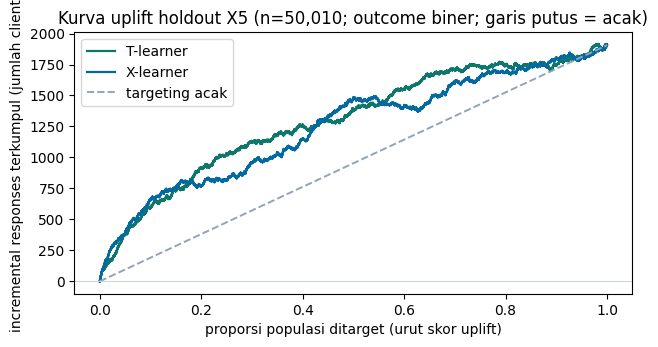

In [6]:
fig, ax = plt.subplots(figsize=(7.2, 3.4))
for score, name, color in [(score_t, "T-learner", "#0f766e"), (score_x, "X-learner", "#0369a1")]:
    frac, gain = uplift_curve(y_te, w_te, score)
    ax.plot(frac, gain, color=color, lw=1.6, label=name)
ax.plot([0, 1], [0, baseline["ate"] * len(te)], color="#94a3b8", lw=1.4, ls="--", label="targeting acak")
ax.axhline(0, color="#cbd5e1", lw=0.8)
ax.set_xlabel("proporsi populasi ditarget (urut skor uplift)")
ax.set_ylabel("incremental responses terkumpul (jumlah client)")
ax.set_title(f"Kurva uplift holdout X5 (n={len(te):,}; outcome biner; garis putus = acak)")
ax.legend()
plt.show()

In [7]:
dec_t = uplift_deciles(y_te, w_te, score_t)
dec_x = uplift_deciles(y_te, w_te, score_x)
print("T-learner:")
print(dec_t.round(4).to_string(index=False))
print()
print("X-learner:")
print(dec_x.round(4).to_string(index=False))

T-learner:
 decile    n  n_treated  n_control  uplift  ci_low  ci_high
      1 5001       2528       2473  0.1198  0.0926   0.1447
      2 5001       2464       2537  0.0644  0.0363   0.0904
      3 5001       2477       2524  0.0415  0.0135   0.0685
      4 5001       2477       2524  0.0285  0.0002   0.0572
      5 5001       2529       2472  0.0217 -0.0033   0.0494
      6 5001       2490       2511  0.0334  0.0087   0.0562
      7 5001       2502       2499  0.0299  0.0045   0.0545
      8 5001       2493       2508  0.0080 -0.0171   0.0319
      9 5001       2476       2525  0.0013 -0.0244   0.0283
     10 5001       2430       2571  0.0257  0.0001   0.0518

X-learner:
 decile    n  n_treated  n_control  uplift  ci_low  ci_high
      1 5001       2516       2485  0.1309  0.1031   0.1593
      2 5001       2498       2503  0.0238 -0.0020   0.0536
      3 5001       2464       2537  0.0384  0.0114   0.0661
      4 5001       2484       2517  0.0384  0.0102   0.0655
      5 5001     

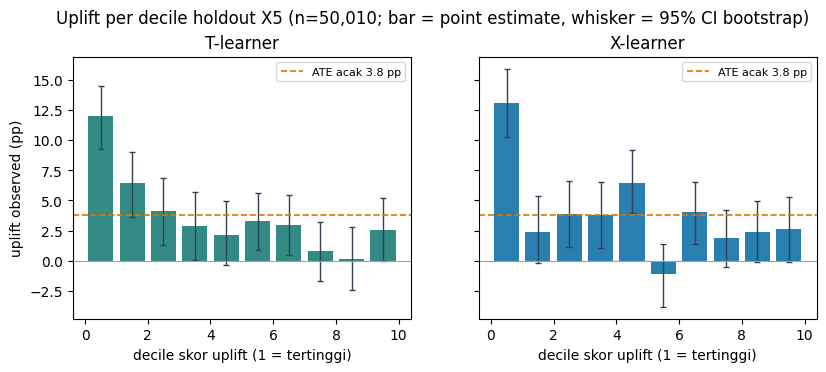

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4), sharey=True)
for ax, dec, name, color in [
    (axes[0], dec_t, "T-learner", "#0f766e"),
    (axes[1], dec_x, "X-learner", "#0369a1"),
]:
    mid = (dec["decile"] - 0.5).to_numpy()
    err = np.vstack([dec["uplift"] - dec["ci_low"], dec["ci_high"] - dec["uplift"]])
    ax.bar(mid, dec["uplift"] * 100, width=0.8, color=color, alpha=0.85)
    ax.errorbar(mid, dec["uplift"] * 100, yerr=err * 100, fmt="none", ecolor="#334155", lw=1, capsize=2)
    ax.axhline(baseline["ate"] * 100, color="#d97706", lw=1.2, ls="--", label=f"ATE acak {baseline['ate']*100:.1f} pp")
    ax.axhline(0, color="#94a3b8", lw=0.8)
    ax.set_xlabel("decile skor uplift (1 = tertinggi)")
    ax.set_title(name)
    ax.legend(fontsize=8)
axes[0].set_ylabel("uplift observed (pp)")
fig.suptitle(f"Uplift per decile holdout X5 (n={len(te):,}; bar = point estimate, whisker = 95% CI bootstrap)", y=1.02)
plt.show()

**Pipeline uplift terbukti bekerja, dengan margin yang moderat.** Kedua meta-learner mengalahkan targeting acak pada holdout 50.010 client: T-learner AUUC skill +344 incremental responses (≈ +0,69 pp per client yang ditarget), X-learner +293 — dan keduanya menempatkan heterogenitas di tempat yang benar. Decile teratas T-learner menunjukkan uplift **+12,0 pp (95% CI 9,3–14,5)** — sekitar tiga kali ATE acak 3,8 pp; X-learner +13,1 pp di decile 1. Decile 8–10 praktis nol (CI memuat nol): sebagian besar populasi berperilaku mendekati efek rata-rata dan daya pilah skor terkonsentrasi di puncak — pola yang realistis untuk promo grocery, bukan kelemahan pipeline.

Kejujuran hasil: skill per client hanya 0,6–0,7 pp — ranking **bukan** pengganda efek — dan decile tengah X-learner tidak monoton (decile 5 lebih tinggi dari decile 4), jadi urutan di bawah decile atas tidak boleh dibaca halus. Untuk operasional berbudget terbatas, yang terbukti adalah *top decile*.

## Batasan dan implikasi untuk tahap observational

- **Validasi metode, bukan angka bisnis Dunnhumby.** X5 panel eksternal (ritel Rusia), target biner *jumlah belanja naik*, fitur terbatas metadata kartu + agregat histori. Angka +12 pp tidak transfer; yang transfer adalah cara pengukuran.
- Target biner membuat Qini klasik relevan di sini; pada tahap Dunnhumby outcome-nya **spend kontinu**, sehingga kurva uplift incremental-spend (bukan Qini biner) yang dipakai — fungsi evaluasinya sama, sudah teruji di atas.
- Kedua learner memakai propensity konstan karena penugasan acak; pada tahap observational propensity dimodelkan dari fitur pra-campaign (termasuk trajektori dan dip spend yang terbukti menutup bias seleksi win-back), evaluasi dibobot overlap, dan **placebo test** wajib: treatment palsu di periode pre harus menghasilkan uplift ≈ 0.
- Split acak 75/25 di sini akan diganti split berbasis waktu campaign + grouping household; setiap decile tetap dilaporkan dengan n dan CI.